# Chicago Crimes — Visualizações Gold Layer

Este notebook gera os gráficos a partir das métricas calculadas na Gold Layer.

**Dataset:** Chicago Crimes (2022–2026)  
**Fonte Gold:** `hdfs://hadoop-master:39000//gold/`

In [1]:
import os
from pyspark.sql import SparkSession
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

spark = SparkSession.builder.appName("Visualizacoes Gold").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

GOLD = os.environ.get("HDFS_ROOT", "hdfs://hadoop-master:39000/<utilizador>") + "/gold"

sns.set_theme(style="darkgrid")
PALETTE = "Set2"

print("Sessão Spark iniciada com sucesso!")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/22 12:37:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/05/22 12:37:49 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/05/22 12:37:49 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/05/22 12:37:49 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.


Sessão Spark iniciada com sucesso!


---
## Gráfico 1 — Total de Crimes por Ano

/tmp/ipykernel_29969/2797430014.py:6: FutureWarning:                            

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="year", y="total", palette=PALETTE, ax=ax)


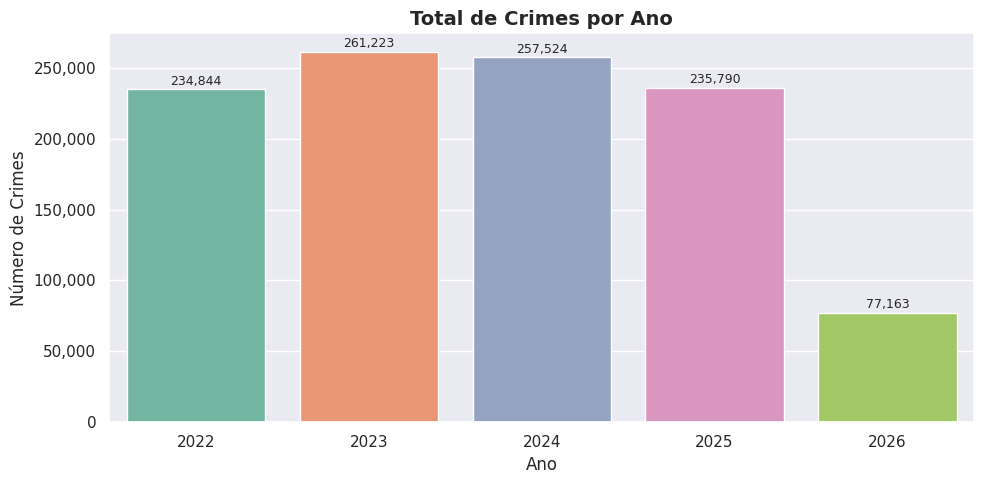

In [2]:
df = spark.read.parquet(f"{GOLD}/crimes_por_tipo_ano/") \
    .groupBy("year").sum("count").withColumnRenamed("sum(count)", "total") \
    .orderBy("year").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df, x="year", y="total", palette=PALETTE, ax=ax)
ax.set_title("Total de Crimes por Ano", fontsize=14, fontweight="bold")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de Crimes")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
            f"{int(bar.get_height()):,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

**Conclusão:** Permite observar a evolução global do volume de criminalidade em Chicago entre 2022 e 2026. O ano de 2026 apresenta naturalmente valores mais baixos por ser um ano ainda em curso.

---
## Gráfico 2 — Top 10 Tipos de Crime (2022–2026)

/tmp/ipykernel_29969/2847097957.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="total", y="crime_type", palette=PALETTE, ax=ax)


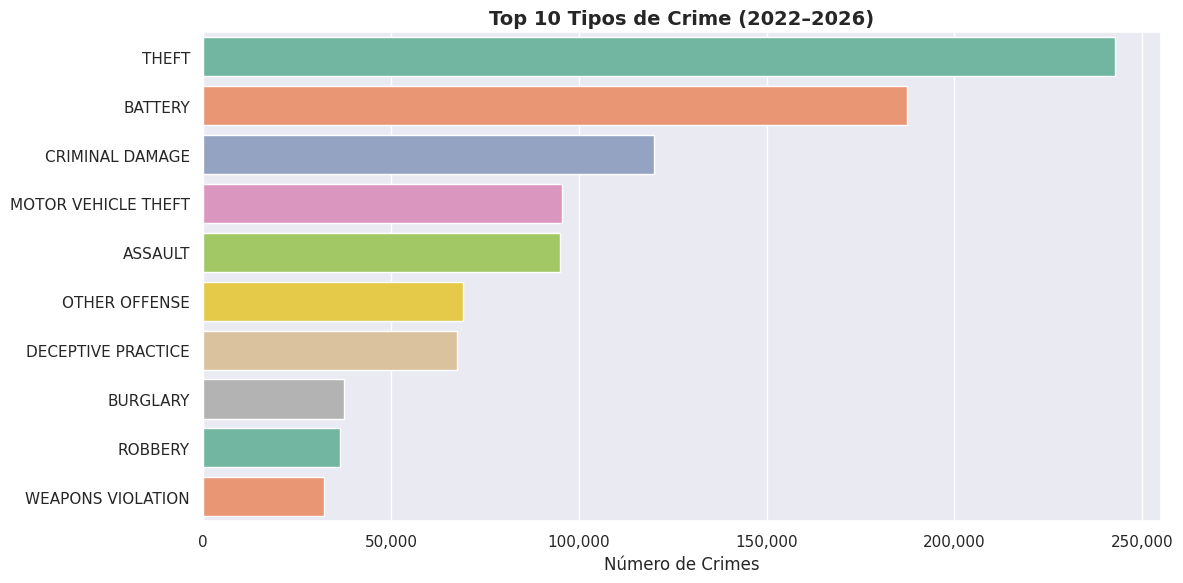

In [3]:
df = spark.read.parquet(f"{GOLD}/crimes_por_tipo_ano/") \
    .groupBy("crime_type").sum("count").withColumnRenamed("sum(count)", "total") \
    .orderBy("total", ascending=False).limit(10).toPandas()

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df, x="total", y="crime_type", palette=PALETTE, ax=ax)
ax.set_title("Top 10 Tipos de Crime (2022–2026)", fontsize=14, fontweight="bold")
ax.set_xlabel("Número de Crimes")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Identifica os crimes mais frequentes no total do período analisado. Esta visão agregada é útil para priorizar recursos policiais e políticas de prevenção.

---
## Gráfico 3 — Evolução dos Top 5 Crimes por Ano

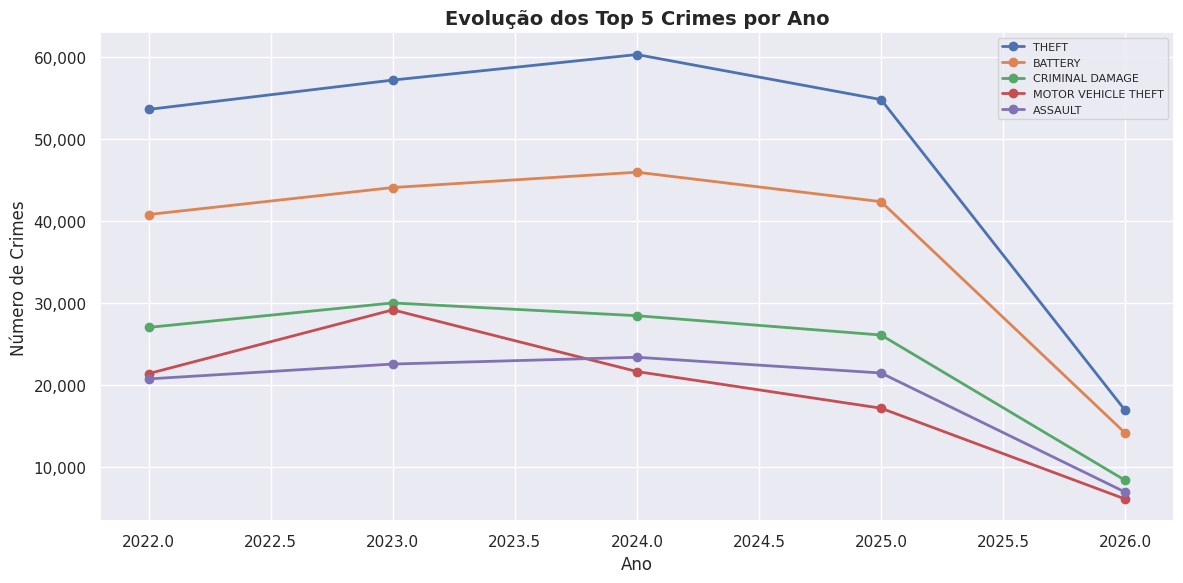

In [4]:
df_all = spark.read.parquet(f"{GOLD}/crimes_por_tipo_ano/").toPandas()
top5 = df_all.groupby("crime_type")["count"].sum().nlargest(5).index.tolist()
df = df_all[df_all["crime_type"].isin(top5)]

fig, ax = plt.subplots(figsize=(12, 6))
for crime in top5:
    d = df[df["crime_type"] == crime].sort_values("year")
    ax.plot(d["year"], d["count"], marker="o", label=crime, linewidth=2)
ax.set_title("Evolução dos Top 5 Crimes por Ano", fontsize=14, fontweight="bold")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de Crimes")
ax.legend(loc="upper right", fontsize=8)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Mostra como os cinco tipos de crime mais frequentes evoluíram individualmente ao longo dos anos. Permite detetar se determinados crimes estão a aumentar, estabilizar ou diminuir.

---
## Gráfico 4 — Distribuição de Crimes por Hora do Dia

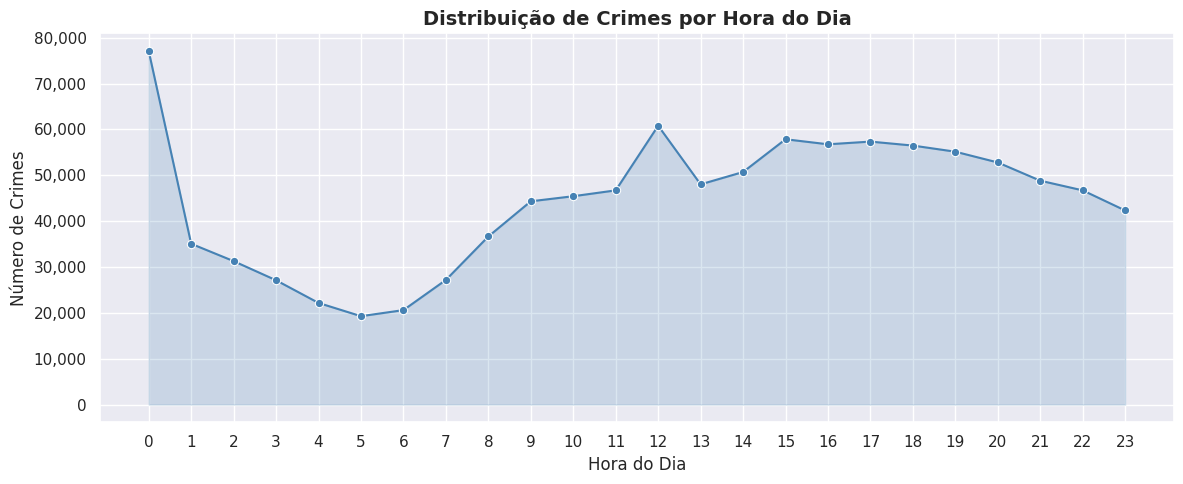

In [5]:
df = spark.read.parquet(f"{GOLD}/crimes_por_hora/").orderBy("crime_hour").toPandas()

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=df, x="crime_hour", y="count", marker="o", color="steelblue", ax=ax)
ax.fill_between(df["crime_hour"], df["count"], alpha=0.2, color="steelblue")
ax.set_title("Distribuição de Crimes por Hora do Dia", fontsize=14, fontweight="bold")
ax.set_xlabel("Hora do Dia")
ax.set_ylabel("Número de Crimes")
ax.set_xticks(range(0, 24))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Revela os padrões temporais da criminalidade ao longo do dia. Esta informação é essencial para otimizar o patrulhamento policial por turnos.

---
## Gráfico 5 — Crimes por Dia da Semana

/tmp/ipykernel_29969/1029463907.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="dia", y="count", palette=PALETTE, ax=ax)


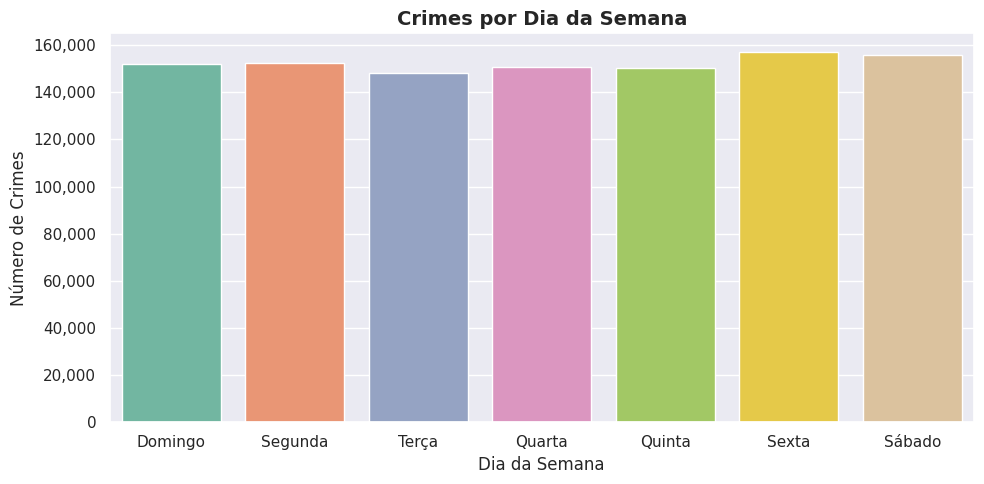

In [6]:
df = spark.read.parquet(f"{GOLD}/crimes_por_dia_semana/").orderBy("day_of_week").toPandas()
dias = {1: "Domingo", 2: "Segunda", 3: "Terça", 4: "Quarta", 5: "Quinta", 6: "Sexta", 7: "Sábado"}
df["dia"] = df["day_of_week"].map(dias)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df, x="dia", y="count", palette=PALETTE, ax=ax)
ax.set_title("Crimes por Dia da Semana", fontsize=14, fontweight="bold")
ax.set_xlabel("Dia da Semana")
ax.set_ylabel("Número de Crimes")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Compara a distribuição de crimes entre os diferentes dias da semana. Útil para planeamento de operações policiais ao longo da semana.

---
## Gráfico 6 — Sazonalidade — Crimes por Mês

/tmp/ipykernel_29969/1161104100.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="mes", y="total", palette=PALETTE, ax=ax)


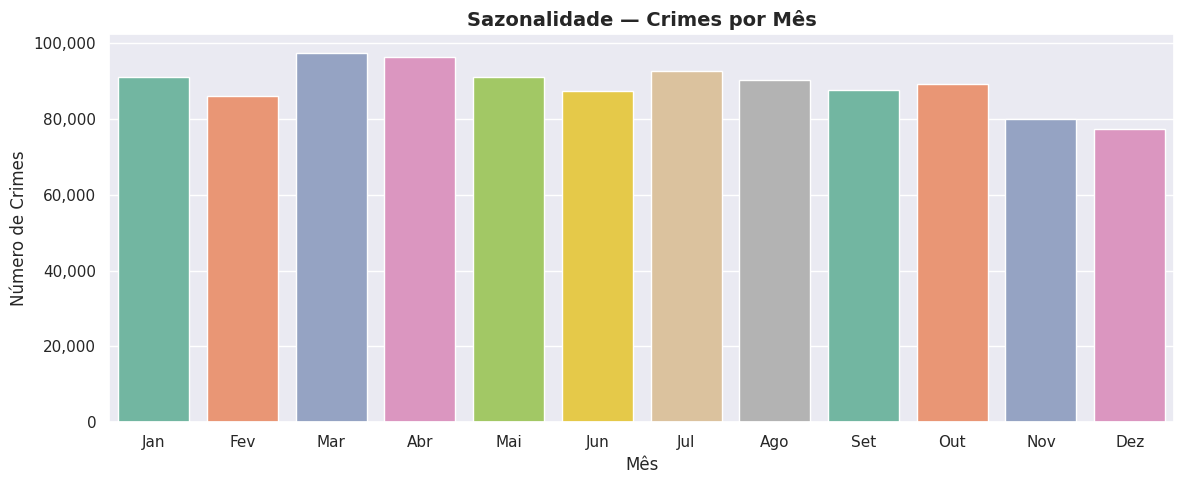

In [7]:
df = spark.read.parquet(f"{GOLD}/crimes_por_mes/") \
    .groupBy("crime_month").sum("count").withColumnRenamed("sum(count)", "total") \
    .orderBy("crime_month").toPandas()
meses = {1:"Jan", 2:"Fev", 3:"Mar", 4:"Abr", 5:"Mai", 6:"Jun",
         7:"Jul", 8:"Ago", 9:"Set", 10:"Out", 11:"Nov", 12:"Dez"}
df["mes"] = df["crime_month"].map(meses)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=df, x="mes", y="total", palette=PALETTE, ax=ax)
ax.set_title("Sazonalidade — Crimes por Mês", fontsize=14, fontweight="bold")
ax.set_xlabel("Mês")
ax.set_ylabel("Número de Crimes")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Evidencia padrões sazonais na criminalidade. Os meses de verão tendem a registar mais crimes, enquanto os meses de inverno com temperaturas extremas apresentam tipicamente valores mais baixos.

---
## Gráfico 7 — Taxa de Arrests por Tipo de Crime

/tmp/ipykernel_29969/2467428003.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="taxa_arrest_pct", y="crime_type", palette="RdYlGn", ax=ax)


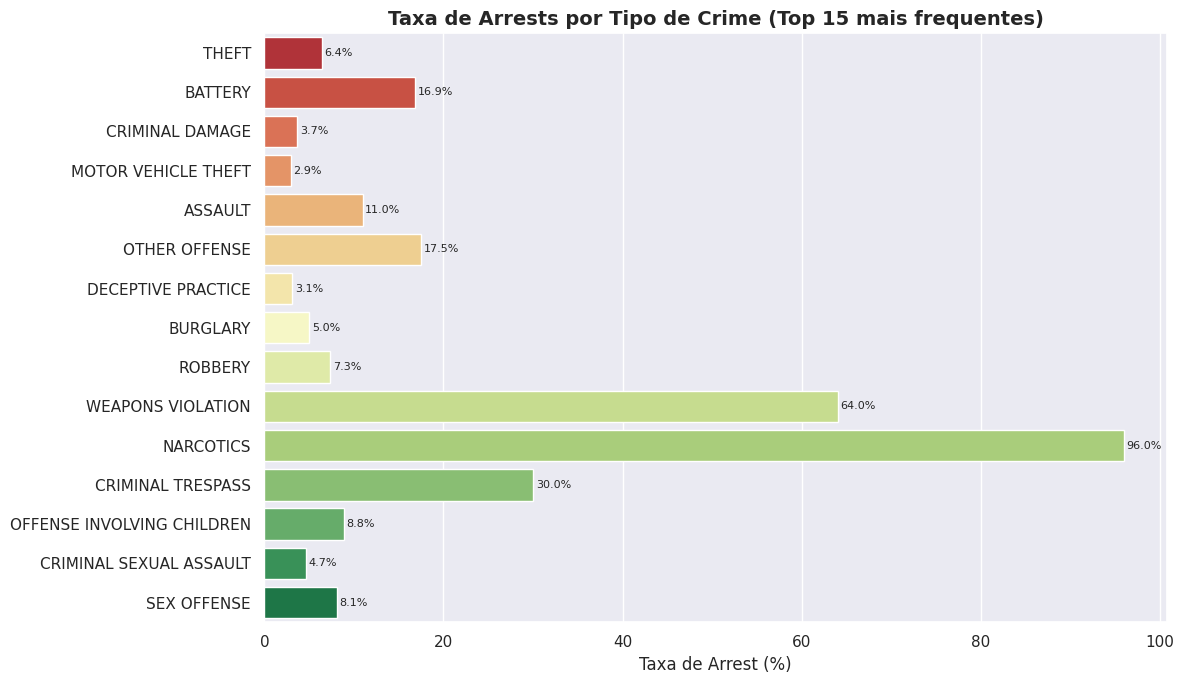

In [8]:
df = spark.read.parquet(f"{GOLD}/taxa_arrests_por_tipo/") \
    .orderBy("total", ascending=False).limit(15).toPandas()

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(data=df, x="taxa_arrest_pct", y="crime_type", palette="RdYlGn", ax=ax)
ax.set_title("Taxa de Arrests por Tipo de Crime (Top 15 mais frequentes)", fontsize=14, fontweight="bold")
ax.set_xlabel("Taxa de Arrest (%)")
ax.set_ylabel("")
for bar in ax.patches:
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f"{bar.get_width():.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Conclusão:** Mostra a eficácia das detenções para cada tipo de crime. Crimes como tráfico de droga e posse de armas tendem a ter taxas de arrest mais elevadas, enquanto furtos têm taxas mais baixas.

---
## Gráfico 8 — Total de Crimes por Distrito Policial

/tmp/ipykernel_29969/306220697.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="district", y="count", palette=PALETTE, ax=ax)


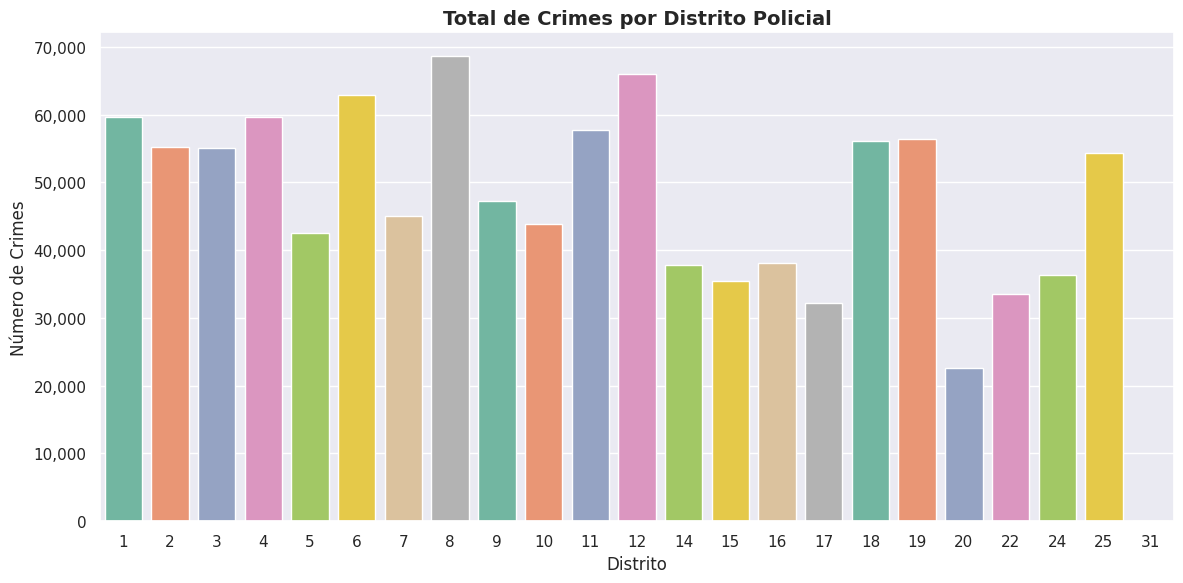

In [9]:
df = spark.read.parquet(f"{GOLD}/crimes_por_distrito/") \
    .orderBy("count", ascending=False).toPandas()

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df, x="district", y="count", palette=PALETTE, ax=ax)
ax.set_title("Total de Crimes por Distrito Policial", fontsize=14, fontweight="bold")
ax.set_xlabel("Distrito")
ax.set_ylabel("Número de Crimes")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Identifica os distritos com maior volume de criminalidade em Chicago. Fundamental para a alocação de recursos policiais por zona geográfica.

---
## Gráfico 9 — Top 15 Community Areas com Mais Crimes

/tmp/ipykernel_29969/1809304086.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="count", y=df["community_area"].astype(str), palette=PALETTE, ax=ax)


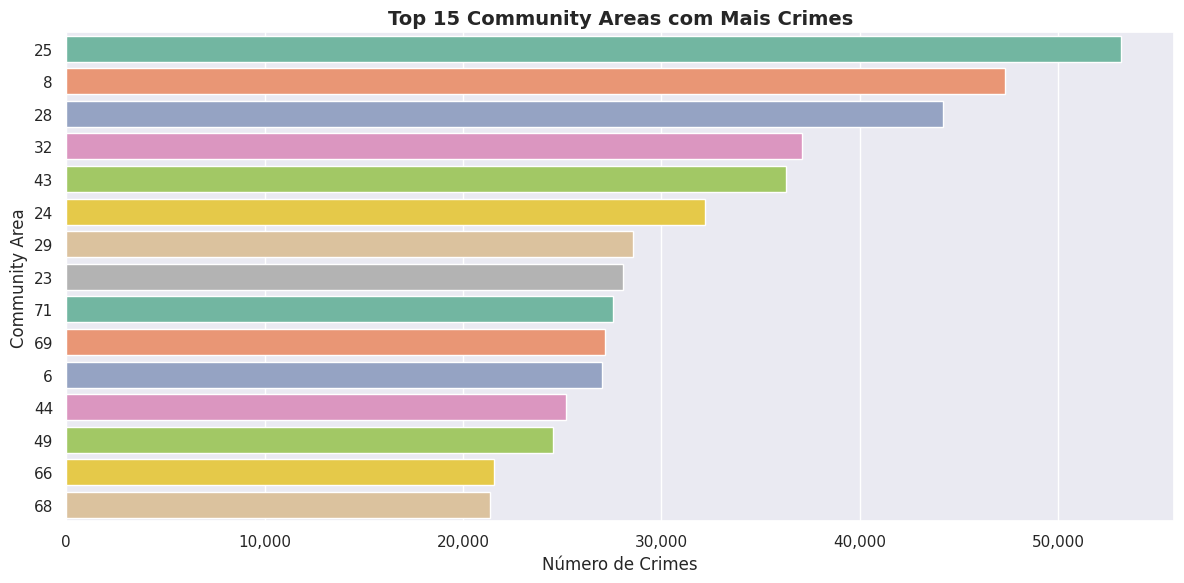

In [10]:
df = spark.read.parquet(f"{GOLD}/crimes_por_community_area/").limit(15).toPandas()

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df, x="count", y=df["community_area"].astype(str), palette=PALETTE, ax=ax)
ax.set_title("Top 15 Community Areas com Mais Crimes", fontsize=14, fontweight="bold")
ax.set_xlabel("Número de Crimes")
ax.set_ylabel("Community Area")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Aprofunda a análise geográfica ao nível dos bairros de Chicago. Permite identificar as zonas com maior concentração de criminalidade para intervenção social e urbana direcionada.

---
## Gráfico 10 — Crimes Domésticos vs Total por Ano

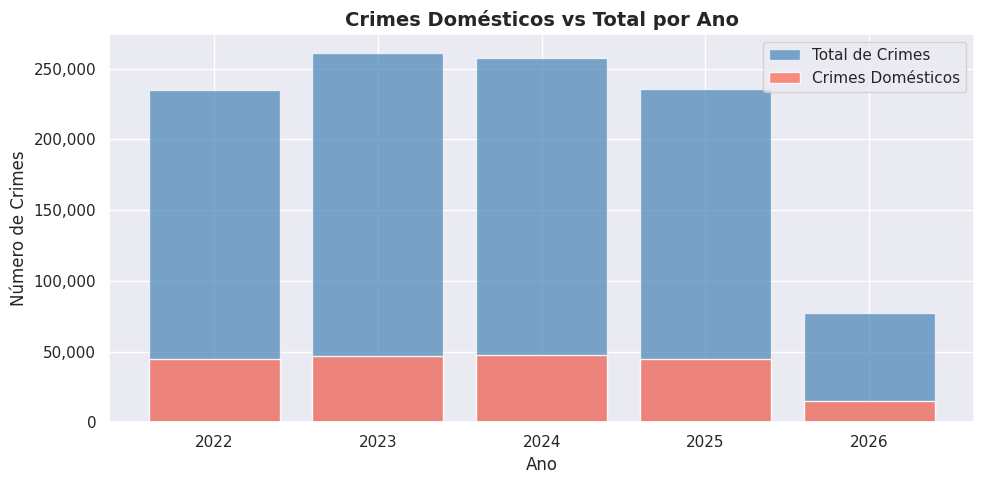

In [11]:
df = spark.read.parquet(f"{GOLD}/crimes_domesticos_por_ano/").orderBy("year").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(df["year"], df["total"], label="Total de Crimes", color="steelblue", alpha=0.7)
ax.bar(df["year"], df["total_domesticos"], label="Crimes Domésticos", color="salmon", alpha=0.9)
ax.set_title("Crimes Domésticos vs Total por Ano", fontsize=14, fontweight="bold")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de Crimes")
ax.legend()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Compara a proporção de crimes domésticos face ao total por ano. Uma percentagem elevada indica necessidade de maior investimento em apoio social e programas de prevenção da violência doméstica.

---
## Gráfico 11 — Crimes por Período do Dia

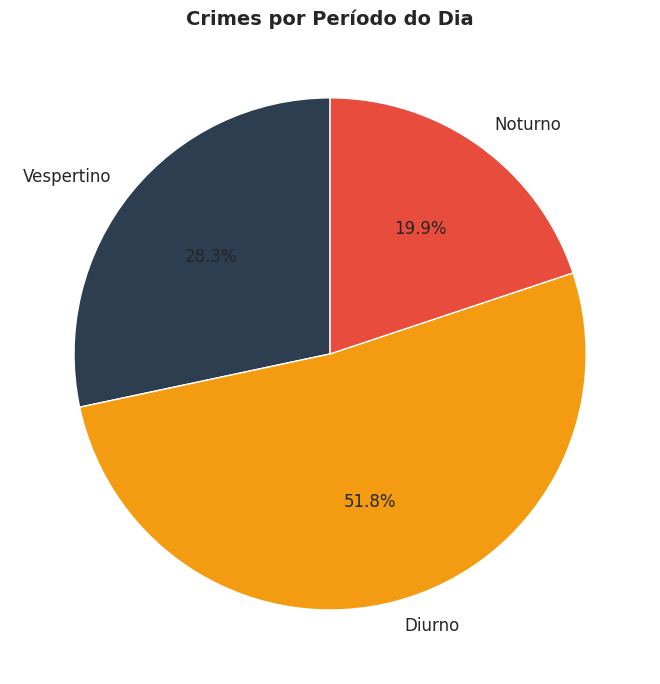

In [12]:
df = spark.read.parquet(f"{GOLD}/crimes_por_periodo_dia/") \
    .groupBy("periodo").sum("count").withColumnRenamed("sum(count)", "total").toPandas()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(df["total"], labels=df["periodo"], autopct="%1.1f%%",
       colors=["#2c3e50", "#f39c12", "#e74c3c"], startangle=90,
       textprops={"fontsize": 12})
ax.set_title("Crimes por Período do Dia", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Conclusão:** Divide os crimes em três períodos — Noturno (00h–06h), Diurno (06h–18h) e Vespertino (18h–00h). Permite perceber em que parte do dia ocorre a maior concentração de criminalidade.

---
## Gráfico 12 — Taxa de Arrests por Distrito Policial

/tmp/ipykernel_29969/1555133662.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="district", y="taxa_arrest_pct", palette="RdYlGn", ax=ax)


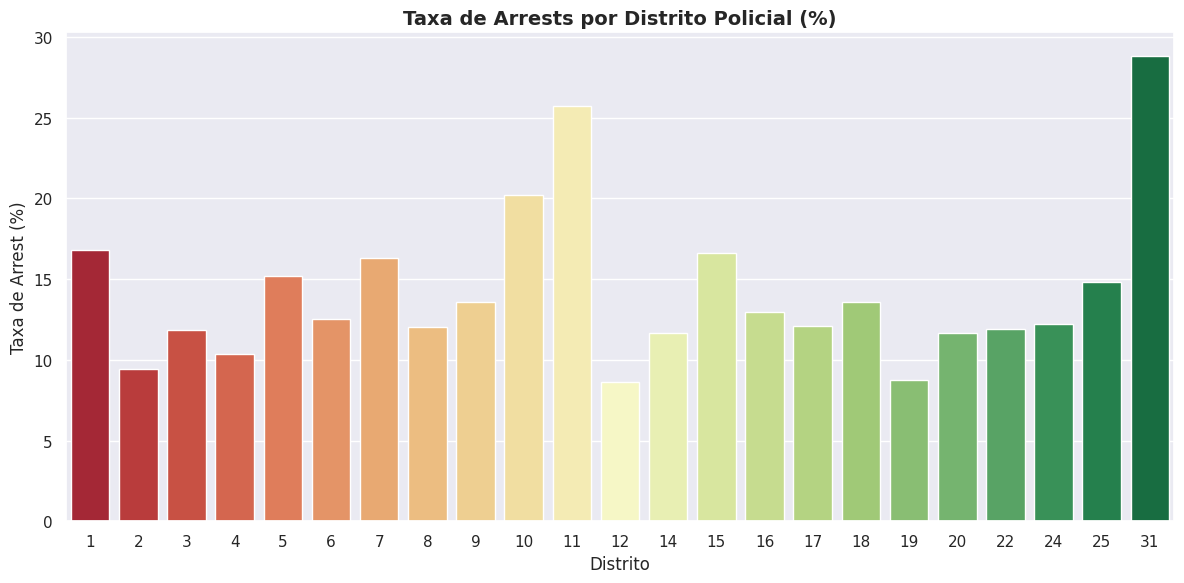

In [13]:
df = spark.read.parquet(f"{GOLD}/taxa_arrests_por_distrito/") \
    .orderBy("taxa_arrest_pct", ascending=False).toPandas()

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df, x="district", y="taxa_arrest_pct", palette="RdYlGn", ax=ax)
ax.set_title("Taxa de Arrests por Distrito Policial (%)", fontsize=14, fontweight="bold")
ax.set_xlabel("Distrito")
ax.set_ylabel("Taxa de Arrest (%)")
plt.tight_layout()
plt.show()

**Conclusão:** Mede a eficácia das detenções por distrito. Distritos com taxas baixas podem necessitar de reforço de meios ou estratégias diferentes de policiamento.

---
## Gráfico 13 — Top 10 Localizações com Mais Crimes

/tmp/ipykernel_29969/3205001922.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="count", y="location_description", palette=PALETTE, ax=ax)


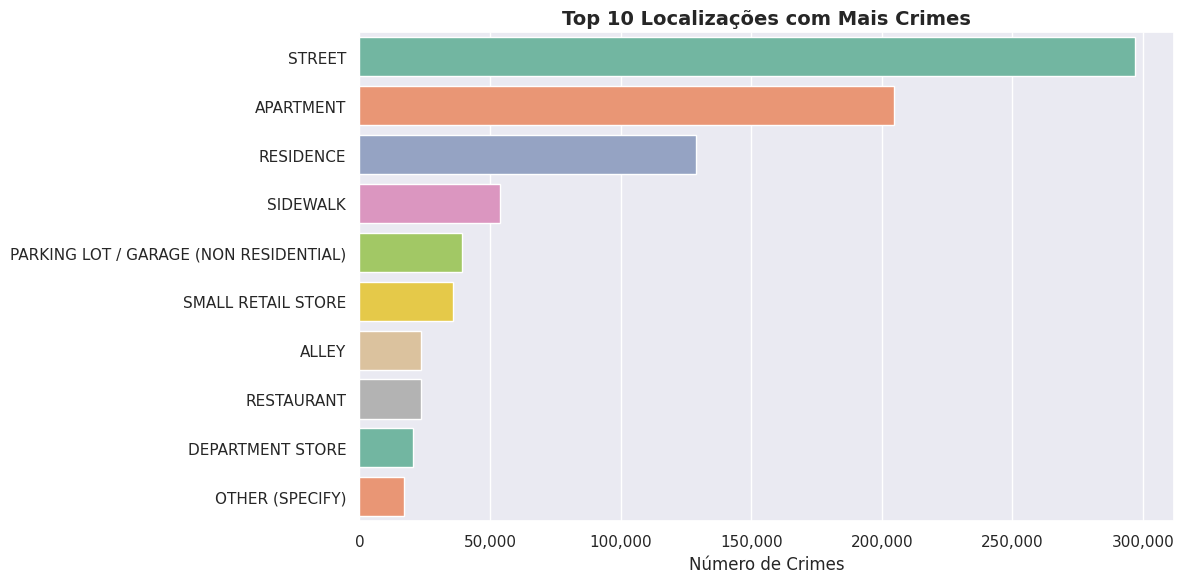

In [14]:
df = spark.read.parquet(f"{GOLD}/crimes_por_localizacao/").limit(10).toPandas()

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df, x="count", y="location_description", palette=PALETTE, ax=ax)
ax.set_title("Top 10 Localizações com Mais Crimes", fontsize=14, fontweight="bold")
ax.set_xlabel("Número de Crimes")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.show()

**Conclusão:** Identifica os tipos de local onde os crimes ocorrem com mais frequência. Orienta estratégias de prevenção situacional, como maior vigilância em locais específicos.

---
## Gráfico 14 — Heatmap: Top 8 Tipos de Crime por Hora do Dia

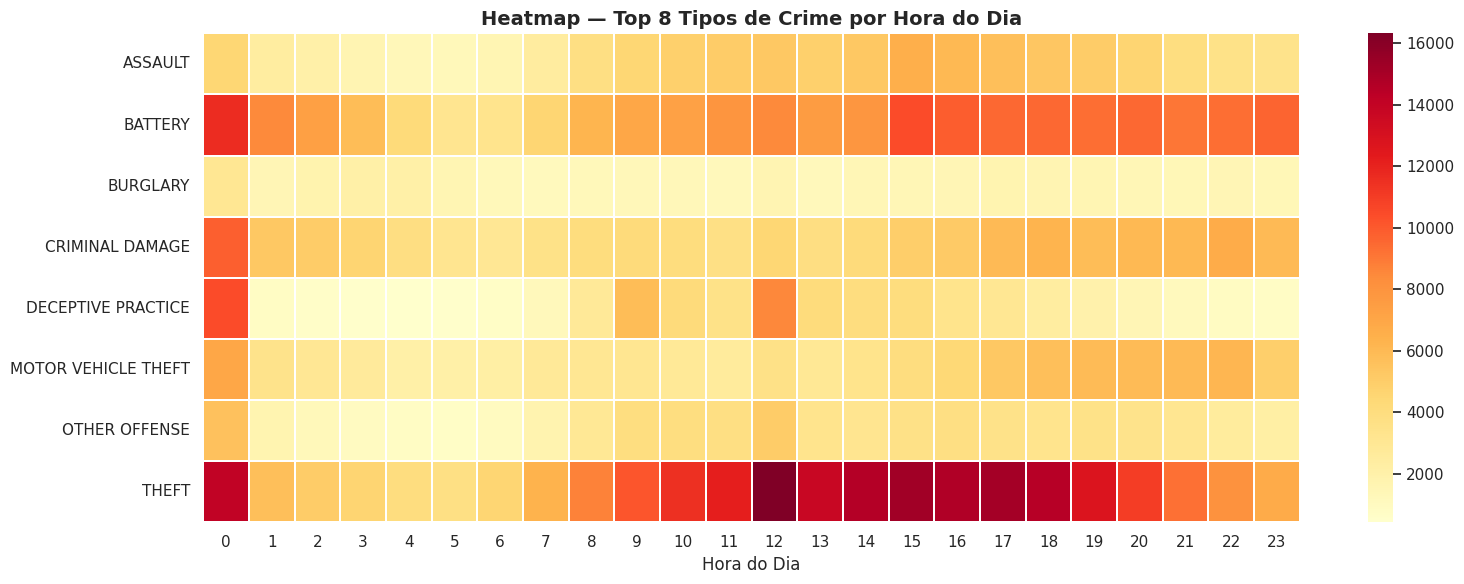

In [15]:
df = spark.read.parquet(f"{GOLD}/crimes_tipo_por_hora/").toPandas()
top8 = df.groupby("crime_type")["count"].sum().nlargest(8).index.tolist()
df = df[df["crime_type"].isin(top8)]
pivot = df.pivot_table(index="crime_type", columns="crime_hour", values="count", fill_value=0)

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(pivot, cmap="YlOrRd", ax=ax, fmt=",d", linewidths=0.3)
ax.set_title("Heatmap — Top 8 Tipos de Crime por Hora do Dia", fontsize=14, fontweight="bold")
ax.set_xlabel("Hora do Dia")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Conclusão:** Cruza tipo de crime e hora do dia num único gráfico. É uma das análises mais ricas do projeto — permite identificar padrões como roubos à tarde ou crimes de armas à noite.

---
## Gráfico 15 — Evolução de WEAPONS VIOLATION ao Longo dos Anos

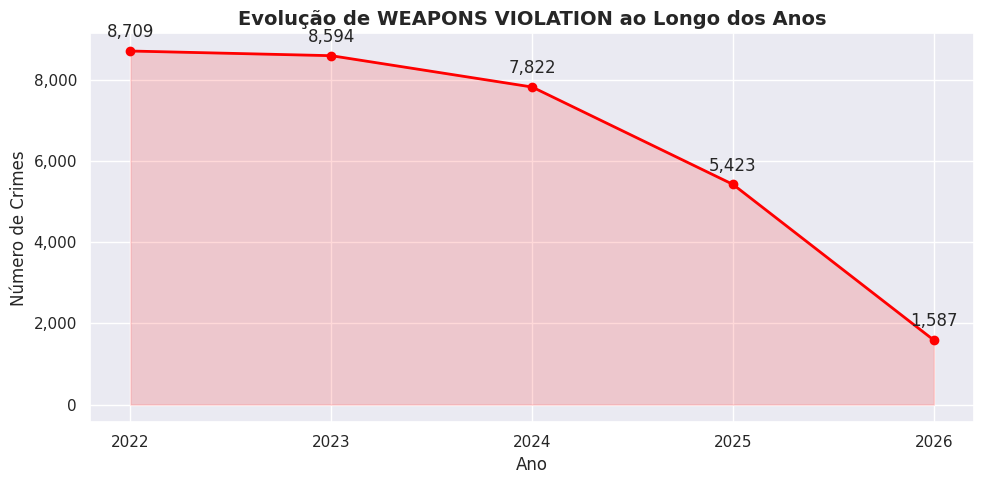

In [16]:
df = spark.read.parquet(f"{GOLD}/crimes_por_tipo_ano/") \
    .filter("crime_type = 'WEAPONS VIOLATION'").orderBy("year").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["year"], df["count"], marker="o", color="red", linewidth=2)
ax.fill_between(df["year"], df["count"], alpha=0.15, color="red")
ax.set_title("Evolução de WEAPONS VIOLATION ao Longo dos Anos", fontsize=14, fontweight="bold")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de Crimes")
ax.set_xticks(df["year"])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for x, y in zip(df["year"], df["count"]):
    ax.annotate(f"{int(y):,}", (x, y), textcoords="offset points", xytext=(0, 10), ha="center")
plt.tight_layout()
plt.show()

**Conclusão:** Analisa especificamente a evolução dos crimes relacionados com armas em Chicago. Uma tendência decrescente pode indicar o impacto de políticas de controlo de armas ou maior eficácia policial nesta categoria.

---
## Fim das Visualizações

In [17]:
spark.stop()
print("Sessão Spark terminada.")

Sessão Spark terminada.
